# Лабораторная 6. Хранение, очистка и структура данных

Вариант 3: цитаты и авторы. HTML из пятой работы дополнен учебным API DummyJSON. Данные проходят raw → clean → mart.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
lab = Path.cwd() if (Path.cwd()/'clean/dataset.parquet').exists() else Path.cwd()/'lab6'
summary=json.loads((lab/'clean/rebuild_summary.json').read_text(encoding='utf-8'))
print(summary)
data=pd.read_parquet(lab/'clean/dataset.parquet')
display(data[['text','author','source','source_record_id','author_birth_year']].head())
display(data.dtypes.to_frame('Тип'))


{'raw_rows': 452, 'clean_rows': 414, 'authors': 98, 'tag_links': 205, 'rejected_rows': 24, 'quality': 'green', 'raw_unchanged': True, 'load': {'rows': 414, 'inserted': 0, 'updated': 0, 'unchanged': 414, 'history': 414}, 'duration_s': 1.5432}


,text,author,source,source_record_id,author_birth_year
0,“The world as we have created it is a process ...,Albert Einstein,quotes_html,000100,1879
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,quotes_html,000101,1965
2,“There are only two ways to live your life. On...,Albert Einstein,quotes_html,000102,1879
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,quotes_html,000103,1775
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,quotes_html,000104,1926


,Тип
business_key,object
text,object
author,object
author_key,object
tags,object
source,object
source_url,object
parser_version,object
collected_at,"datetime64[ns, UTC]"
source_record_id,string[python]


## 1. Сырые данные и происхождение

Raw не перезаписывается. В каждой строке сохранены источник, URL, время UTC, версия парсера и HTTP-статус. 32 записи с учебными дефектами явно помечены.

In [2]:
raw=[]
for path in (lab/'raw').glob('*.jsonl'):
    raw.extend(json.loads(s) for s in path.read_text(encoding='utf-8').splitlines() if s)
print('Сырых строк:',len(raw),'синтетических случаев:',sum(bool(r.get('_synthetic')) for r in raw))
display(pd.DataFrame(raw)[['_source','_source_url','_collected_at','_parser_version','_status']].head())


Сырых строк: 452 синтетических случаев: 32


,_source,_source_url,_collected_at,_parser_version,_status
0,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
1,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
2,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
3,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
4,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200


## 2. Шесть этапов очистки

Порядок: текст → ключ → типы → пропуски → дубли → бизнес-правила. Все удаления имеют причину.

In [3]:
display(pd.read_csv(lab/'clean/cleaning_protocol.csv'))
rejects=[json.loads(s) for s in (lab/'clean/rejects.jsonl').read_text(encoding='utf-8').splitlines()]
display(pd.DataFrame(rejects).groupby(['stage','field']).size().to_frame('Записей'))


,step,before,after,changed,removed,note
0,1. Нормализация текста,452,452,17,0,"NFKC, NBSP, zero-width, пробелы"
1,2. Бизнес-ключ и URL,452,452,452,0,SHA-ключ у всех строк; tracking-URL: 8
2,3. Типизация,452,446,446,6,"UTC, числовой год, строковый ID; ошибки в rejects"
3,4. Пропуски,446,434,0,12,"Текст, автор и URL обязательны; неизвестный го..."
4,"5. Полные, ключевые и почти-дубли",434,420,0,14,Сохранена самая свежая запись
5,6. Бизнес-правила и контракт,420,414,0,6,Полный pydantic-контракт; поле и причина в rej...


Записей
stage field                                    
3     collected_at / author_birth_year        6
4     author_raw                              6
      text_raw                                6
6     tags                                    6

## 3. CSV, JSON Lines и Parquet

Время — медиана семи чтений на том же наборе. Pandas автоматически распознаёт числовые строки в CSV и JSONL: ведущие нули требуют явно заданного dtype. Parquet сохраняет строковый тип и UTC.

In [4]:
display(pd.read_csv(lab/'clean/format_benchmark.csv'))
print('Исходный строковый ID в Parquet:',repr(data['source_record_id'].iloc[0]))


,format,bytes,read_all_ms,read_three_ms,date_dtype,id_dtype,id_example
0,CSV,137434,8.3477,6.2272,object,int64,100
1,JSONL,209284,20.9737,21.0878,"datetime64[ns, UTC]",int64,100
2,Parquet,72574,6.1466,4.2139,"datetime64[ns, UTC]",string,100


Исходный строковый ID в Parquet: '000100'


## 4. Контракт pydantic

Модель находится в src/contract.py. Проверяются диапазоны, теги, часовой пояс и согласованность ключей и длины текста.

In [5]:
display(pd.DataFrame(json.loads((lab/'clean/contract_examples.json').read_text(encoding='utf-8'))))


,check,result,message
0,Пустой текст,rejected,String should have at least 8 characters
1,Короткое имя,rejected,String should have at least 2 characters
2,Неверный тег,rejected,"Value error, Тег должен быть непустым slug в н..."
3,Дата без зоны,rejected,"Value error, Нужен часовой пояс UTC"
4,Неверный ключ,rejected,"Value error, Бизнес-ключ не соответствует текс..."
5,Неверная длина,rejected,Input should be greater than 7
6,Неверный источник URL,rejected,"Value error, URL не соответствует источнику"


## 5. UPSERT, ограничения и история

Обычная БД — db/warehouse.db. Отдельная db/idempotency_demo.db содержит три демонстрационных загрузки; в третьей изменены теги двух записей.

In [6]:
import sqlite3
demo=json.loads((lab/'clean/idempotency.json').read_text(encoding='utf-8'))
display(pd.DataFrame(demo['runs']))
print('updated_at не изменён на повторе:',demo['updated_at_preserved'])
display(pd.DataFrame(demo['constraints']))
with sqlite3.connect(lab/'db/warehouse.db') as connection:
    display(pd.read_sql_query('SELECT * FROM quotes_by_source',connection))
    print('Нарушения внешних ключей:',connection.execute('PRAGMA foreign_key_check').fetchall())


,run,rows,inserted,updated,unchanged,history
0,A,414,414,0,0,414
1,B,414,0,0,414,414
2,C,414,0,2,412,416


updated_at не изменён на повторе: True


,check,result,message
0,duplicate_key,rejected,"UNIQUE constraint failed: quotes.source, quote..."
1,check,rejected,CHECK constraint failed: text_length BETWEEN 8...
2,not_null,rejected,NOT NULL constraint failed: quotes.text


,source,quotes,mean_length
0,dummyjson_api,320,79.44
1,quotes_html,94,121.23


Нарушения внешних ключей: []


## 6. Качество и остановка mart

Восемь метрик имеют зелёный, жёлтый и красный пороги. Команда python -m src.rebuild --force-red демонстрирует остановку до изменения mart.

In [7]:
quality=json.loads((lab/'clean/quality.json').read_text(encoding='utf-8'))
display(pd.DataFrame(quality['metrics']))
print('Итог:',quality['verdict'])


,metric,value,green,yellow,direction,status,reason
0,mandatory_completeness,1.000000,1.0,0.99,min,green,Обязательные поля нужны для загрузки
1,optional_completeness,0.227053,0.1,0.05,min,green,Год рождения доступен у части HTML-авторов
2,unique_keys,1.000000,1.0,0.99,min,green,Уникальный бизнес-ключ
3,validity,0.946903,0.9,0.80,min,green,До 10% явно внесённых дефектов
4,reject_share,0.053097,0.1,0.20,max,green,До 10% учебной отбраковки
5,business_consistency,1.000000,1.0,0.99,min,green,Полный контракт и согласованность полей
6,median_age_days,0.261923,30.0,60.00,max,green,Для учебных метаданных допустим возраст до месяца
7,volume_change,0.000000,0.1,0.20,max,green,Изменение объёма до 10%


Итог: green


## Как посчитана валидность

Контракт проверяется отдельно для каждой сырой строки после нормализации, до удаления дублей. Проверка бизнес-правил также использует полную модель.

In [8]:
print('Прошли контракт:', quality['contract_valid_raw'], 'из', quality['raw_rows'])
print('Валидность:', round(100 * quality['contract_valid_raw'] / quality['raw_rows'], 2), '%')

Прошли контракт: 428 из 452
Валидность: 94.69 %


## 7. Аналитические представления и партиции

quotes_by_author


,name,quotes,mean_length
0,Rumi,56,80.46
1,Muhammad Ali,41,102.12
2,Ali ibn Abi Talib (R.A),25,84.76
3,Abdul Kalam,22,112.05
4,Albert Einstein,18,86.94
5,Mark Twain,17,74.41
6,Abu Bakr (R.A),15,68.13
7,Umar ibn Al-Khattāb (R.A),14,69.86


quotes_by_source


,source,quotes,mean_length
0,dummyjson_api,320,79.44
1,quotes_html,94,121.23


popular_tags


,tag,quotes
0,humor,12
1,inspirational,12
2,life,11
3,love,11
4,books,10
5,reading,7
6,truth,4
7,attributed-no-source,3


{'partitions': ['dt=2026-10-07', 'dt=2026-10-14'], 'selected': 'dt=2026-10-07', 'rows': 86}


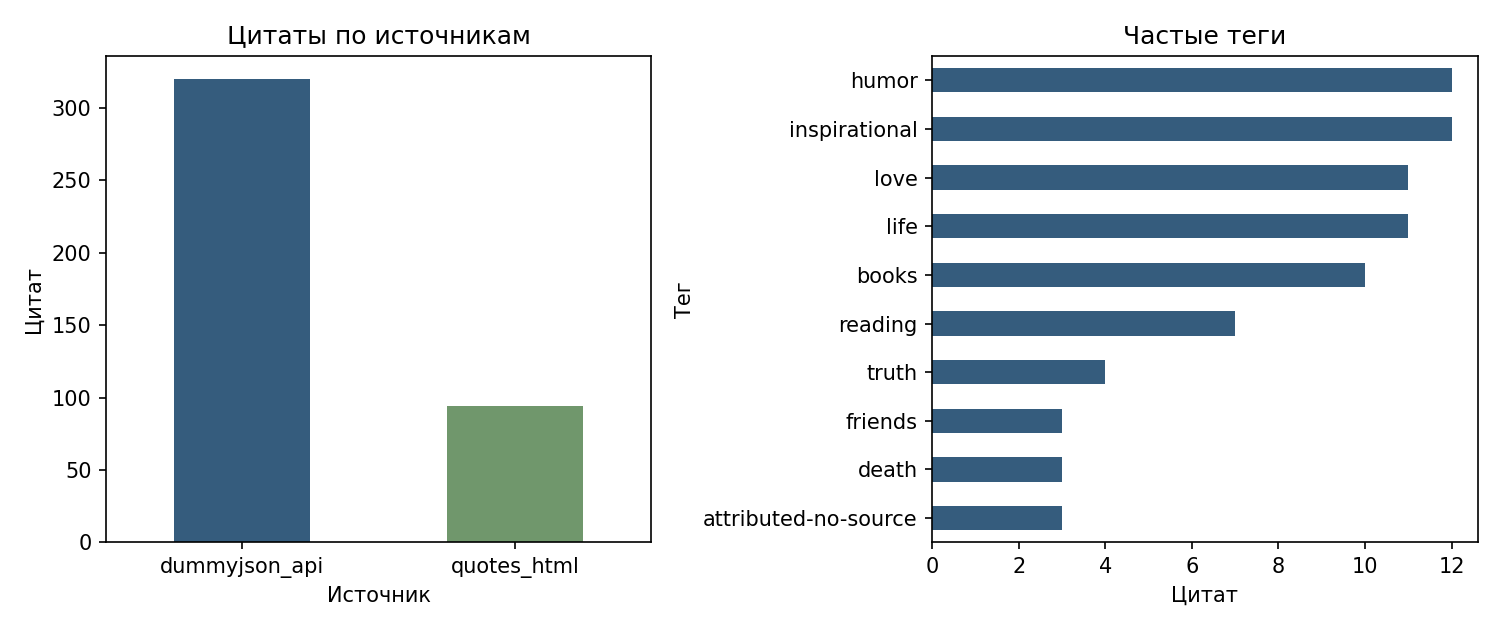

In [9]:
for name in ('quotes_by_author','quotes_by_source','popular_tags'):
    print(name)
    display(pd.read_parquet(lab/'mart/views'/f'{name}.parquet').head(8))
print(json.loads((lab/'mart/partition_read.json').read_text(encoding='utf-8')))
display(Image(filename=str(lab/'figures/mart.png')))


## 8. Сравнение с n8n

n8n читает подмножество сохранённых источников, нормализует поля, отделяет брак, удаляет дубли и сразу пишет CSV. Полной схемы pydantic, истории изменений и UPSERT в выбранном CSV-экспорте нет.

In [10]:
nocode=pd.read_csv(lab/'nocode/nocode_result.csv',dtype=str).fillna('')
bad=pd.read_csv(lab/'nocode/rejects.csv',dtype=str).fillna('')
print('n8n:',len(nocode),'чистых строк;',len(bad),'отбракованных')
joined=nocode.merge(data,on='business_key',suffixes=('_n8n','_python'),validate='one_to_one')
assert len(joined)==len(nocode)
for field in ('text','author'):
    assert joined[field+'_n8n'].eq(joined[field+'_python']).all()
print('Ключи, тексты и авторы совпали')
display(nocode[['text','author','source']].head())
display(bad[['reason']])


n8n:

 34 чистых строк; 3 отбракованных
Ключи, тексты и авторы совпали


,text,author,source
0,“The world as we have created it is a process ...,Albert Einstein,quotes_html
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,quotes_html
2,“There are only two ways to live your life. On...,Albert Einstein,quotes_html
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,quotes_html
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,quotes_html


,reason
0,text: длина вне диапазона
1,author: пустое или короткое имя
2,collected_at: неверная дата


## Повторное построение партиций

Повторная пересборка заменяет файлы затронутых партиций, не добавляя копии тех же строк.

In [11]:
snap=pd.read_parquet(lab/'mart/snapshots')
assert len(snap)==len(data) and snap['business_key'].nunique()==len(data)
print('Во всех партициях:',len(snap),'строк, уникальных ключей:',snap['business_key'].nunique())
display(pd.DataFrame(json.loads((lab/'mart/snapshot_validation.json').read_text(encoding='utf-8'))['runs']))

Во всех партициях:

 414 строк, уникальных ключей: 414


,rows,unique_keys,files
0,414,414,"[snapshots/dt=2026-10-07/part-0.parquet, snaps..."
1,414,414,"[snapshots/dt=2026-10-07/part-0.parquet, snaps..."
